# Why renovation savings are not additive

Run a four-case experiment to distinguish independent measure savings from a combined package response.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

This four-case experiment contains baseline, insulation only, glazing only and their combination. Every case shares the original geometry, weather and use, so the effect of combining measures can be distinguished from accidentally changing other inputs.

Define independent savings as `(baseline − insulation) + (baseline − glazing)` and combined savings as `baseline − combined`. Their difference is the interaction quantity used below. The workflow figure puts simulation between edited inputs and comparison: input changes alone cannot tell you whether savings will add linearly.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Define a matched factorial experiment

All cases share weather, geometry and use. Insulation and glazing are applied individually and then together with dated audit records.

### Read the code and output

The two individual variants are each derived from the baseline; the combined case is derived from the insulation variant and then receives glazing replacement. The input table checks that the intended parameters changed. The audit dates express sequence, not staged simulation of building use over several years.

In [2]:
b=building()
insulation=AddInsulation(element="wall",layer=b.envelope.wall.layers[0].updated(thickness_m=.1))
glazing=ReplaceGlazing(glazing=GlazingSpec(u_value_w_m2k=1.1,solar_heat_gain_coefficient=.5))
a=apply_renovation(b,insulation,effective_date="2026-01-01")
g=apply_renovation(b,glazing,effective_date="2026-01-01")
ab=apply_renovation(a,glazing,effective_date="2026-01-02")
cases={"baseline":b,"insulation":a,"glazing":g,"combined":ab}
table([{ "case":name,"wall_U_W_m2K":s.envelope.wall.u_value_w_m2k,"glazing_U_W_m2K":s.facade.glazing.u_value_w_m2k} for name,s in cases.items()])

,case,wall_U_W_m2K,glazing_U_W_m2K
0,baseline,0.247669,1.8
1,insulation,0.152960,1.8
2,glazing,0.247669,1.1
3,combined,0.152960,1.1


,case,wall_U_W_m2K,glazing_U_W_m2K
0,baseline,0.247669,1.8
1,insulation,0.152960,1.8
2,glazing,0.247669,1.1
3,combined,0.152960,1.1


## Run the four real cases

The model resolves interactions through its thermal calculation. No assumption of additivity is made before running.

### Read the code and output

The four annual outputs use independent directories to prevent accidental reuse of old engine files. Read the baseline beside each single-measure case before interpreting the combined value. A small single-measure saving can still interact with controls or other envelope changes.

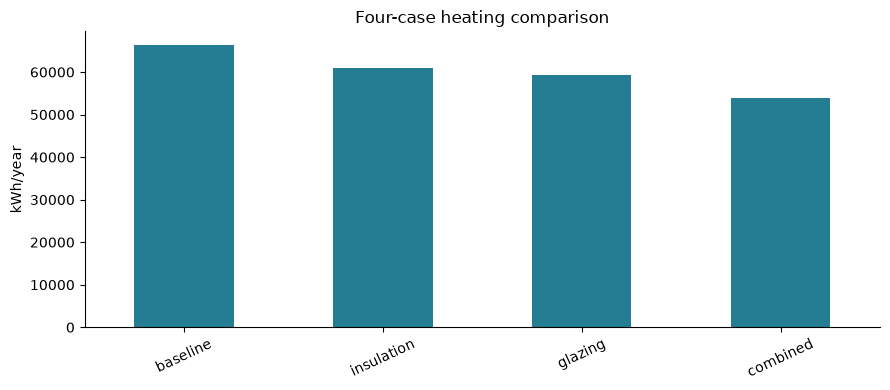

In [3]:
results={name:EnergyPlusRunner(engine()).run(spec,OUT/name) for name,spec in cases.items()}
heating=pd.Series({name:r.scalars["space_heating_demand_kwh"] for name,r in results.items()})
bars(heating.to_dict(),"kWh/year","Four-case heating comparison")

## Quantify the interaction

Compare the actual combined saving with the sum of individual savings. A small interaction in this one case is not a guarantee for other climates, controls or envelopes.

### Read the code and output

A positive interaction means the combined saving exceeds the sum of individual savings under this definition; a negative interaction means it is smaller. Neither sign by itself establishes good or bad performance. State the definition and baseline whenever presenting the quantity to avoid ambiguous “synergy” claims.

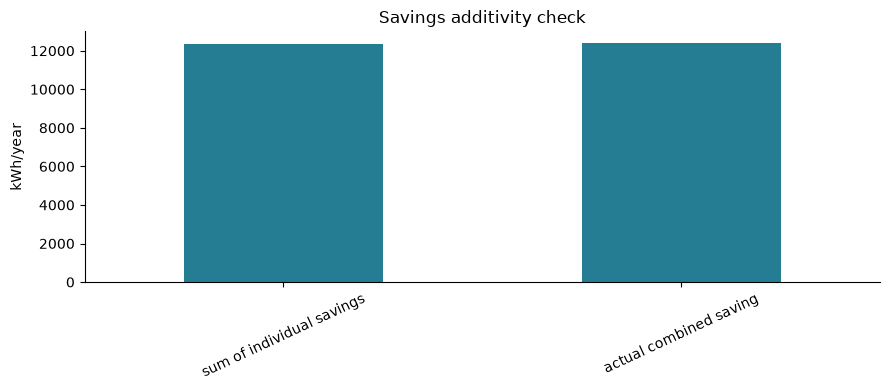

,field,value
0,interaction_kwh,40.30576949438546
1,definition,combined saving minus sum of individual savings


In [4]:
individual=(heating.baseline-heating.insulation)+(heating.baseline-heating.glazing)
combined=heating.baseline-heating.combined
bars({"sum of individual savings":individual,"actual combined saving":combined},"kWh/year","Savings additivity check")
table({"interaction_kwh":combined-individual,"definition":"combined saving minus sum of individual savings"})
assert len(ab.renovations)==2 and len(b.renovations)==0

## Interpretation and next experiment

Use matched factorial comparisons for a few important assumptions before extrapolating package effects across a stock.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.